## Mini-Project 1: Fetching and Displaying a Weather Forecast with Python Web APIs

Course: Object-Oriented Programming  
Project: Weather Forecast Retrieval and Display  
Student: Pariyo Ponyano Prescort  
Institution: Uganda Christian University
Registration No:
Access No: B38640

This project demonstrates how Python can communicate with web APIs to retrieve geographic and weather information.

The project uses:

1. Open-Meteo Geocoding API
2. Open-Meteo Forecast API
3. MET Norway Locationforecast API

The project also demonstrates HTTP fundamentals, error handling, retries, JSON parsing, pandas data processing, visualization and offline testing.

In [ ]:
LOCATION = "Entebbe"
UNIVERSITY_EMAIL = "YOUR_UNIVERSITY_EMAIL@example.com"
FORECAST_DAYS = 5
REQUEST_TIMEOUT = 10

In [6]:
import os
import sys
import json
import time
import urllib.request
import urllib.parse
from pathlib import Path
from datetime import datetime

import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Make the repository root importable
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.weather_api import (
    WeatherAPIError,
    geocode,
    select_location,
    get_forecast,
    forecast_to_dataframe,
    weather_code_description,
    get_met_norway_forecast,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Project root:", PROJECT_ROOT)
print("Imports completed.")

Project root: c:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\PYTHON PROGRAMMING\Weather forecast
Imports completed.


In [ ]:
## Part A: HTTP Fundamentals

#The first demonstration uses Python's standard `urllib` libraries. The second uses the third-party `requests` library. Both send a geocoding query to Open-Meteo, but they differ in how requests, query parameters, headers, and exceptions are handled.

In [7]:
#Geocoding using urllib

def geocode_with_urllib(name: str, timeout: float = 10) -> dict:
    """Search for a location using urllib and return decoded JSON."""
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = urllib.parse.urlencode({
        "name": name,
        "count": 10,
        "language": "en",
        "format": "json",
    })
    request = urllib.request.Request(
        f"{url}?{params}",
        headers={"Accept": "application/json"},
    )

    try:
        with urllib.request.urlopen(request, timeout=timeout) as response:
            return json.loads(response.read().decode("utf-8"))
    except (
        urllib.error.URLError,
        TimeoutError,
        json.JSONDecodeError,
    ) as exc:
        raise RuntimeError(f"urllib geocoding failed: {exc}") from exc


urllib_result = geocode_with_urllib(LOCATION, REQUEST_TIMEOUT)
print(json.dumps(urllib_result, indent=2)[:2000])

{
  "results": [
    {
      "id": 233508,
      "name": "Entebbe",
      "latitude": 0.05621,
      "longitude": 32.47949,
      "elevation": 1151.0,
      "feature_code": "PPL",
      "country_code": "UG",
      "admin1_id": 234594,
      "admin2_id": 448224,
      "admin3_id": 7732225,
      "admin4_id": 8657745,
      "timezone": "Africa/Kampala",
      "population": 102600,
      "country_id": 226074,
      "country": "Uganda",
      "admin1": "Central Region",
      "admin2": "Wakiso District",
      "admin3": "Entebbe Municipality",
      "admin4": "Division B"
    },
    {
      "id": 6297374,
      "name": "Entebbe Airport",
      "latitude": 0.04239,
      "longitude": 32.4435,
      "elevation": 1152.0,
      "feature_code": "AIRP",
      "country_code": "UG",
      "admin1_id": 234594,
      "admin2_id": 448224,
      "admin3_id": 7732225,
      "admin4_id": 8657745,
      "timezone": "Africa/Kampala",
      "country_id": 226074,
      "country": "Uganda",
      "admin1": "

In [8]:
#Geocoding using requests, with status and response time

def geocode_with_requests(name: str, timeout: float = 10) -> tuple[dict, dict]:
    """Return geocoding JSON and HTTP diagnostic information."""
    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": name,
        "count": 10,
        "language": "en",
        "format": "json",
    }

    start = time.perf_counter()

    try:
        response = requests.get(
            url,
            params=params,
            headers={"Accept": "application/json"},
            timeout=timeout,
        )
        elapsed = time.perf_counter() - start
        response.raise_for_status()

        diagnostics = {
            "status_code": response.status_code,
            "content_type": response.headers.get("Content-Type", "Not provided"),
            "response_time_seconds": round(elapsed, 4),
            "request_url": response.url,
        }
        return response.json(), diagnostics

    except (requests.RequestException, ValueError) as exc:
        raise RuntimeError(f"requests geocoding failed: {exc}") from exc


requests_result, diagnostics = geocode_with_requests(
    LOCATION, REQUEST_TIMEOUT
)

display(pd.DataFrame([diagnostics]))

,status_code,content_type,response_time_seconds,request_url
0,200,application/json; charset=utf-8,1.4326,https://geocoding-api.open-meteo.com/v1/search...


In [9]:
#Display geocoding candidates and handle ambiguity

def display_candidates(data: dict) -> pd.DataFrame:
    """Convert geocoding results into a readable candidate table."""
    candidates = data.get("results", [])

    columns = [
        "name", "admin1", "country", "latitude",
        "longitude", "timezone",
    ]

    if not candidates:
        return pd.DataFrame(columns=columns)

    return pd.DataFrame(candidates).reindex(columns=columns)


candidates_df = display_candidates(requests_result)
display(candidates_df)

if candidates_df.empty:
    print(f"No locations found for {LOCATION!r}. Check the spelling.")
elif len(candidates_df) == 1:
    print("One matching location was found.")
else:
    print(
        f"{len(candidates_df)} candidates were found. "
        "Check the country and administrative region before selecting."
    )

,name,admin1,country,latitude,longitude,timezone
0,Entebbe,Central Region,Uganda,0.05621,32.47949,Africa/Kampala
1,Entebbe Airport,Central Region,Uganda,0.04239,32.44350,Africa/Kampala


2 candidates were found. Check the country and administrative region before selecting.


In [13]:
#compare HTTP approaches

### Comparing `urllib` and `requests`

#Code length: 'requests' generally needs less code to send a GET request and read JSON.
#Query encoding: `urllib.parse.urlencode` explicitly builds an encoded query string; `requests` encodes parameters supplied through `params=`.
#Error handling: `urllib` raises standard-library exceptions. With `requests`, `raise_for_status()` converts unsuccessful HTTP status codes into exceptions.
#Headers and timeouts: Both support custom headers and timeouts. `requests` makes these settings convenient to read and maintain.
#Dependencies: `urllib` is included with Python, while `requests` must be installed separately.
#Conclusion: `urllib` is useful for demonstrating standard-library HTTP fundamentals. `requests` is convenient for the main project because its API is readable and its HTTP error handling is straightforward.

In [10]:
#Retrieve the main forecast

# The reusable implementation lives in src/weather_api.py.
location_data = geocode(LOCATION)

if not location_data:
    raise ValueError(
        f"No geocoding results for {LOCATION!r}. "
        "Choose a valid city or town."
    )

selected_location = select_location(location_data)

latitude = float(selected_location["latitude"])
longitude = float(selected_location["longitude"])

print("Selected location:", selected_location)
print("Latitude:", latitude)
print("Longitude:", longitude)

forecast_json = get_forecast(
    latitude,
    longitude,
    FORECAST_DAYS,
)

print("Forecast received successfully.")


Multiple locations were found:

1. Entebbe, Central Region, Uganda (0.05621, 32.47949)
2. Entebbe Airport, Central Region, Uganda (0.04239, 32.4435)
Please enter a number.
Please enter a number.
Please enter a number.
Please enter a number.
Please enter a number.
Please enter a number.
Please enter a number.
Selected location: {'id': 233508, 'name': 'Entebbe', 'latitude': 0.05621, 'longitude': 32.47949, 'elevation': 1151.0, 'feature_code': 'PPL', 'country_code': 'UG', 'admin1_id': 234594, 'admin2_id': 448224, 'admin3_id': 7732225, 'admin4_id': 8657745, 'timezone': 'Africa/Kampala', 'population': 102600, 'country_id': 226074, 'country': 'Uganda', 'admin1': 'Central Region', 'admin2': 'Wakiso District', 'admin3': 'Entebbe Municipality', 'admin4': 'Division B'}
Latitude: 0.05621
Longitude: 32.47949
Forecast received successfully.


In [11]:
#Convert the forecast to a DataFrame

forecast_df = forecast_to_dataframe(forecast_json)

display(forecast_df)

,Date,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h),Weather Code,Weather Description
0,2026-10-13,26.3,19.0,0.0,10.7,3,Overcast
1,2026-10-14,26.7,19.5,0.1,12.2,51,Light drizzle
2,2026-10-15,26.4,20.3,1.2,10.6,51,Light drizzle
3,2026-10-16,24.3,20.2,4.7,15.2,80,Slight rain showers
4,2026-10-17,23.1,19.6,13.5,9.4,81,Moderate rain showers


In [14]:
#Add readable weather descriptions

def describe_weather(code: int) -> str:
    """Return a readable description for a WMO weather code."""
    description = weather_code_description(code)

    if isinstance(description, str):
        return description

    return str(description)


if "weather_code" in forecast_df.columns:
    forecast_df["weather_description"] = (
        forecast_df["weather_code"].apply(describe_weather)
    )
elif "Weather Code" in forecast_df.columns:
    forecast_df["Weather Description"] = (
        forecast_df["Weather Code"].apply(describe_weather)
    )

display(forecast_df)

,Date,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h),Weather Code,Weather Description
0,2026-10-13,26.3,19.0,0.0,10.7,3,Overcast
1,2026-10-14,26.7,19.5,0.1,12.2,51,Light drizzle
2,2026-10-15,26.4,20.3,1.2,10.6,51,Light drizzle
3,2026-10-16,24.3,20.2,4.7,15.2,80,Slight rain showers
4,2026-10-17,23.1,19.6,13.5,9.4,81,Moderate rain showers


In [15]:
#Text summary of the forecast

print(f"WEATHER FORECAST: {LOCATION}")
print("=" * 55)
print("Forecast timezone:", forecast_json.get("timezone", "Not provided"))
print("Forecast latitude:", forecast_json.get("latitude", latitude))
print("Forecast longitude:", forecast_json.get("longitude", longitude))
print("Data source: Open-Meteo Forecast API")
print("Source: https://open-meteo.com/")
print()

display(forecast_df.describe(include="all").transpose())

WEATHER FORECAST: Entebbe
Forecast timezone: Africa/Kampala
Forecast latitude: 0.10544816
Forecast longitude: 32.478565
Data source: Open-Meteo Forecast API
Source: https://open-meteo.com/



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,5,5,2026-10-13,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Max Temperature (°C),5.0,NaN,NaN,NaN,25.36,1.580506,23.1,24.3,26.3,26.4,26.7
Min Temperature (°C),5.0,NaN,NaN,NaN,19.72,0.535724,19.0,19.5,19.6,20.2,20.3
Precipitation (mm),5.0,NaN,NaN,NaN,3.9,5.695173,0.0,0.1,1.2,4.7,13.5
Max Wind Speed (km/h),5.0,NaN,NaN,NaN,11.62,2.234278,9.4,10.6,10.7,12.2,15.2
Weather Code,5.0,NaN,NaN,NaN,53.2,31.704889,3.0,51.0,51.0,80.0,81.0
Weather Description,5,4,Light drizzle,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Available forecast columns: ['Date', 'Max Temperature (°C)', 'Min Temperature (°C)', 'Precipitation (mm)', 'Max Wind Speed (km/h)', 'Weather Code', 'Weather Description']


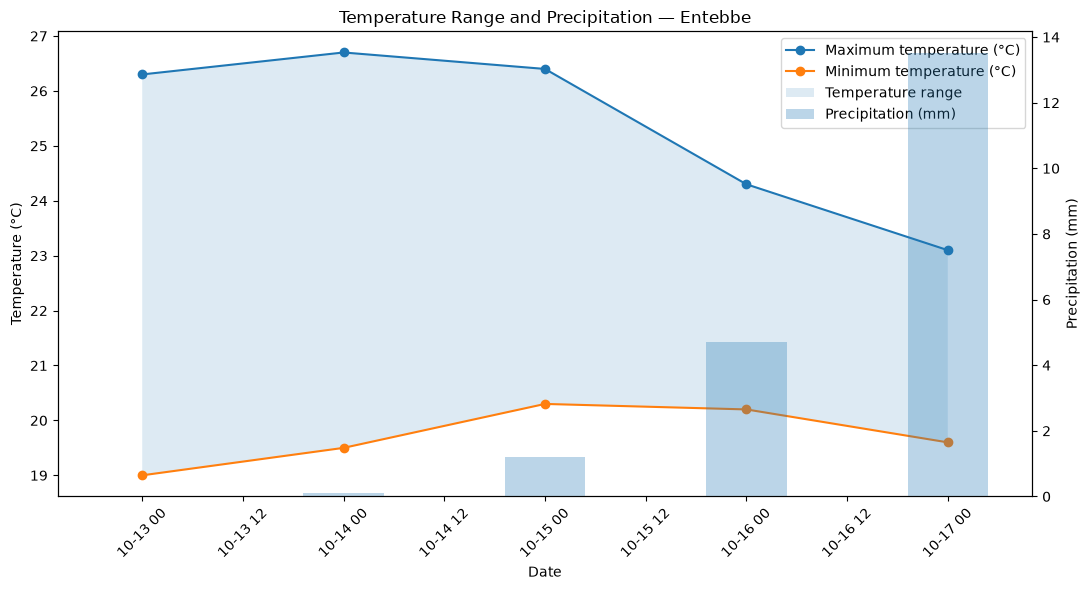

In [18]:
#Plot temperature range and precipitation


import pandas as pd
import matplotlib.pyplot as plt

# 1. Check the actual column names returned by the parser
print("Available forecast columns:", forecast_df.columns.tolist())

# 2. Normalize column names for easier matching
column_lookup = {
    str(column).strip().lower().replace(" ", "_"): column
    for column in forecast_df.columns
}


def find_column(*candidates):
    """Find a DataFrame column using alternative names."""
    for candidate in candidates:
        candidate = candidate.lower().replace(" ", "_")

        # First try an exact match
        if candidate in column_lookup:
            return column_lookup[candidate]

        # Then try a partial match
        for lower_name, original_name in column_lookup.items():
            if candidate in lower_name:
                return original_name

    return None


# 3. Identify the required columns
date_col = find_column("date", "time")
max_temp_col = find_column(
    "temperature_2m_max",
    "maximum_temperature",
    "max_temperature",
    "maximum"
)
min_temp_col = find_column(
    "temperature_2m_min",
    "minimum_temperature",
    "min_temperature",
    "minimum"
)
rain_col = find_column(
    "precipitation_sum",
    "precipitation",
    "rainfall",
    "rain"
)

# 4. Stop with a useful message if a column is missing
missing = []
if date_col is None:
    missing.append("date/time")
if max_temp_col is None:
    missing.append("maximum temperature")
if min_temp_col is None:
    missing.append("minimum temperature")
if rain_col is None:
    missing.append("precipitation/rainfall")

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        f"Available columns: {forecast_df.columns.tolist()}"
    )

# 5. Prepare data for plotting
plot_df = forecast_df.copy()
plot_df[date_col] = pd.to_datetime(plot_df[date_col])

for col in [max_temp_col, min_temp_col, rain_col]:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

plot_df = plot_df.sort_values(date_col)

# 6. Plot temperatures and precipitation
fig, ax1 = plt.subplots(figsize=(11, 6))

ax1.plot(
    plot_df[date_col],
    plot_df[max_temp_col],
    marker="o",
    label="Maximum temperature (°C)"
)

ax1.plot(
    plot_df[date_col],
    plot_df[min_temp_col],
    marker="o",
    label="Minimum temperature (°C)"
)

ax1.fill_between(
    plot_df[date_col],
    plot_df[min_temp_col],
    plot_df[max_temp_col],
    alpha=0.15,
    label="Temperature range"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.bar(
    plot_df[date_col],
    plot_df[rain_col],
    width=0.4,
    alpha=0.3,
    label="Precipitation (mm)"
)
ax2.set_ylabel("Precipitation (mm)")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")

plt.title(f"Temperature Range and Precipitation — {LOCATION}")
fig.tight_layout()
plt.show()


In [19]:
#Save the forecast as CSV

output_path = Path("weather_forecast.csv")
forecast_df.to_csv(output_path, index=False)

print(f"Forecast saved to {output_path.resolve()}")

Forecast saved to C:\Users\Lenovo\Documents\MSDS\SEM 1\OBJECT ORIENTED PROGRAMMING\PYTHON PROGRAMMING\Weather forecast\weather_forecast.csv


In [21]:
#Load your saved sample JSON for offline testing


from pathlib import Path
import json
import pandas as pd
from IPython.display import display

# 1. Define the path to your saved sample JSON file.
# Change the filename if your saved file has a different name.
SAMPLE_JSON_PATH = Path("sample_weather.json")

# 2. Load the saved JSON or use fallback sample data.
if SAMPLE_JSON_PATH.exists():
    with SAMPLE_JSON_PATH.open("r", encoding="utf-8") as file:
        sample_json = json.load(file)

    print(f"Loaded offline sample: {SAMPLE_JSON_PATH}")

else:
    sample_json = {
        "latitude": 0.0562,
        "longitude": 32.4795,
        "timezone": "Africa/Kampala",
        "daily": {
            "time": [
                "2026-10-11", "2026-10-12", "2026-10-13",
                "2026-10-14", "2026-10-15"
            ],
            "temperature_2m_max": [27.2, 26.8, 27.5, 26.9, 28.0],
            "temperature_2m_min": [19.5, 19.2, 19.8, 19.4, 20.0],
            "precipitation_sum": [0.0, 3.2, 5.7, 1.2, 0.0],
            "wind_speed_10m_max": [12.5, 15.2, 18.1, 14.0, 11.8],
            "weather_code": [1, 61, 63, 80, 0],
        },
    }

    print("Saved sample not found; using offline sample data.")

# 3. Convert daily JSON data into a DataFrame.
sample_daily = sample_json["daily"]

sample_df = pd.DataFrame({
    "date": sample_daily["time"],
    "temperature_max_c": sample_daily["temperature_2m_max"],
    "temperature_min_c": sample_daily["temperature_2m_min"],
    "precipitation_mm": sample_daily["precipitation_sum"],
    "wind_speed_max_kmh": sample_daily["wind_speed_10m_max"],
    "weather_code": sample_daily["weather_code"],
})

# 4. Display the sample data.
display(sample_df)


Saved sample not found; using offline sample data.


,date,temperature_max_c,temperature_min_c,precipitation_mm,wind_speed_max_kmh,weather_code
0,2026-10-11,27.2,19.5,0.0,12.5,1
1,2026-10-12,26.8,19.2,3.2,15.2,61
2,2026-10-13,27.5,19.8,5.7,18.1,63
3,2026-10-14,26.9,19.4,1.2,14.0,80
4,2026-10-15,28.0,20.0,0.0,11.8,0


In [22]:
#At least five offline assertions

# These assertions check the sample data without making any HTTP requests.

assert len(sample_df) == 5
assert sample_df["date"].iloc[0] == "2026-10-11"
assert sample_df["temperature_max_c"].max() == 28.0
assert sample_df["temperature_min_c"].min() == 19.2
assert round(sample_df["precipitation_mm"].sum(), 1) == 10.1
assert sample_df["weather_code"].tolist() == [1, 61, 63, 80, 0]
assert sample_json["timezone"] == "Africa/Kampala"

print("All seven offline sample-data assertions passed.")

All seven offline sample-data assertions passed.


In [23]:
#Demonstrate invalid inputs safely

# Invalid city: this should return no candidates or raise a clear API exception.
try:
    invalid_city_results = geocode("InvalidCityNameXYZ123")
    if not invalid_city_results:
        print("Invalid city handled: no locations found.")
    else:
        print("The API returned candidates for the test string.")
except (WeatherAPIError, RuntimeError, requests.RequestException, ValueError) as exc:
    print("Invalid city handled with an error:", exc)

Invalid city handled with an error: No location found for 'InvalidCityNameXYZ123'.


In [24]:
#Invalid latitude

try:
    invalid_forecast = get_forecast(999.0, longitude, FORECAST_DAYS)
    print("The API returned a response for an invalid latitude; inspect it:", invalid_forecast)
except (WeatherAPIError, RuntimeError, requests.RequestException, ValueError) as exc:
    print("Invalid latitude handled:", exc)

Invalid latitude handled: Latitude must be between -90 and 90.


In [25]:
#Simulate a network failure offline

def simulated_network_failure():
    """Simulate a network error without making a real network request."""
    raise requests.ConnectionError("Simulated connection failure for testing.")


try:
    simulated_network_failure()
except requests.ConnectionError as exc:
    print("Simulated network failure handled:", exc)

Simulated network failure handled: Simulated connection failure for testing.


In [26]:
#Demonstrate a tiny timeout

try:
    # A very small timeout demonstrates how timeout failures are reported.
    # Depending on network conditions, the request may still complete.
    tiny_timeout_result, tiny_timeout_diagnostics = geocode_with_requests(
        LOCATION, timeout=0.000001
    )
    print("Request completed despite the tiny timeout.")
    display(pd.DataFrame([tiny_timeout_diagnostics]))
except (RuntimeError, requests.RequestException) as exc:
    print("Tiny timeout handled:", exc)

Tiny timeout handled: requests geocoding failed: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Entebbe&count=10&language=en&format=json (Caused by ConnectTimeoutError(<HTTPSConnection(host='geocoding-api.open-meteo.com', port=443) at 0x262c22ed310>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=1e-06)'))


In [27]:
#Retrieve the second source: Norway MET

# Cell 21: Retrieve the second source: Norway MET Locationforecast

met_url = (
    "https://api.met.no/weatherapi/locationforecast/2.0/compact"
)

met_headers = {
    "User-Agent": f"UCU-WeatherForecast/1.0 contact: {UNIVERSITY_EMAIL}"
}

try:
    met_response = requests.get(
        met_url,
        params={"lat": latitude, "lon": longitude},
        headers=met_headers,
        timeout=REQUEST_TIMEOUT,
    )
    met_response.raise_for_status()
    met_json = met_response.json()

    print("Norway MET forecast retrieved successfully.")
    print("Source: https://api.met.no/weatherapi/locationforecast/2.0")
    print("HTTP status:", met_response.status_code)

except (requests.RequestException, ValueError) as exc:
    met_json = None
    print("Norway MET request failed:", exc)

Norway MET forecast retrieved successfully.
Source: https://api.met.no/weatherapi/locationforecast/2.0
HTTP status: 200


In [28]:
#Inspect Norway MET response

if met_json is not None:
    properties = met_json.get("properties", {})
    timeseries = properties.get("timeseries", [])

    print("Number of forecast time steps:", len(timeseries))

    if timeseries:
        first_entry = timeseries[0]
        print("First forecast time:", first_entry.get("time"))
        display(pd.json_normalize(first_entry))
else:
    print("No MET data available to display.")

Number of forecast time steps: 92
First forecast time: 2026-10-13T07:00:00Z


,time,data.instant.details.air_pressure_at_sea_level,data.instant.details.air_temperature,data.instant.details.cloud_area_fraction,data.instant.details.relative_humidity,data.instant.details.wind_from_direction,data.instant.details.wind_speed,data.next_12_hours.summary.symbol_code,data.next_1_hours.summary.symbol_code,data.next_1_hours.details.precipitation_amount,data.next_6_hours.summary.symbol_code,data.next_6_hours.details.precipitation_amount
0,2026-10-13T07:00:00Z,1017.9,23.6,97.7,76.3,68.0,2.3,lightrainshowers_day,rain,0.7,rainshowers_day,1.6


In [29]:
#Compare forecast sources

print("FORECAST SOURCE COMPARISON")
print("=" * 55)
print("Primary source: Open-Meteo")
print("Primary forecast rows:", len(forecast_df))
print("Secondary source: Norway MET Locationforecast")

if met_json is not None:
    met_timeseries = met_json.get("properties", {}).get("timeseries", [])
    print("Secondary forecast time steps:", len(met_timeseries))
else:
    print("Secondary source unavailable during this run.")

print(
    "\nNote: The providers may use different forecast models, "
    "update schedules, and time resolutions. Their values may differ."
)

FORECAST SOURCE COMPARISON
Primary source: Open-Meteo
Primary forecast rows: 5
Secondary source: Norway MET Locationforecast
Secondary forecast time steps: 92

Note: The providers may use different forecast models, update schedules, and time resolutions. Their values may differ.


In [30]:
# Test the actual project parser using saved JSON, without an API request.

parsed_sample_df = forecast_to_dataframe(sample_json)

assert isinstance(parsed_sample_df, pd.DataFrame)
assert len(parsed_sample_df) == 5
assert not parsed_sample_df.empty

print("Parser returned a valid DataFrame.")
display(parsed_sample_df.head())

Parser returned a valid DataFrame.


,Date,Max Temperature (°C),Min Temperature (°C),Precipitation (mm),Max Wind Speed (km/h),Weather Code,Weather Description
0,2026-10-11,27.2,19.5,0.0,12.5,1,Mainly clear
1,2026-10-12,26.8,19.2,3.2,15.2,61,Slight rain
2,2026-10-13,27.5,19.8,5.7,18.1,63,Moderate rain
3,2026-10-14,26.9,19.4,1.2,14.0,80,Slight rain showers
4,2026-10-15,28.0,20.0,0.0,11.8,0,Clear sky


In [31]:
# Final checks before submission

assert LOCATION.strip()
assert FORECAST_DAYS >= 1
assert SAMPLE_JSON_PATH is not None
assert len(sample_df) >= 1
assert sample_df["date"].notna().all()
assert sample_df["temperature_max_c"].notna().all()
assert sample_df["temperature_min_c"].notna().all()
assert (
    sample_df["temperature_max_c"] >= sample_df["temperature_min_c"]
).all()
assert (sample_df["precipitation_mm"] >= 0).all()
assert (sample_df["wind_speed_max_kmh"] >= 0).all()

print("Final validation passed.")
print("Notebook is ready for a Restart & Run All check.")
print("Remember to commit project_weather.ipynb and the supporting project files.")

Final validation passed.
Notebook is ready for a Restart & Run All check.
Remember to commit project_weather.ipynb and the supporting project files.
